# Modelling, part 1: preparing the data

**Goal of this notebook.** Prepare everything the models will need, without training any model yet:

1. build the **target** (a composite index of business digitalisation);
2. check that the target makes sense;
3. define the **explanatory variables** and check their multicollinearity (VIF);
4. build the **groups** (the country) needed for country-grouped cross-validation;
5. save a clean `model_data.csv` for the next notebook.

**Why not train a model yet?** With only 81 observations, the choices made here (what the target is, which variables are included, how the data are split) matter more than the choice of algorithm. Doing them carefully now avoids having to redo the models later.

**How to use it.** Run one cell at a time with `Shift + Enter`, read the text above each cell first, and look at each output before moving on.

**Contents**
0. Setup
1. Loading the data
2. Building the target
3. Does the target make sense?
4. Explanatory variables and multicollinearity
5. Groups and country-grouped cross-validation
6. Saving the model data
7. Checklist before moving on

## 0. Setup

Same logic as in the EDA notebook: import the libraries and locate the project's root folder, so the notebook works from `notebooks/` or from the root.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = next((p for p in [Path(".."), Path(".")] if (p / "data" / "processed").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed: open the project from its root folder.")

FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current chart in outputs/figures/ (call it BEFORE plt.show())."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

COUNTRY_NAMES = {
    "AT": "Austria", "BE": "Belgium", "BG": "Bulgaria", "CY": "Cyprus", "CZ": "Czechia",
    "DE": "Germany", "DK": "Denmark", "EE": "Estonia", "EL": "Greece", "ES": "Spain",
    "FI": "Finland", "FR": "France", "HR": "Croatia", "HU": "Hungary", "IE": "Ireland",
    "IT": "Italy", "LT": "Lithuania", "LU": "Luxembourg", "LV": "Latvia", "MT": "Malta",
    "NL": "Netherlands", "PL": "Poland", "PT": "Portugal", "RO": "Romania",
    "SE": "Sweden", "SI": "Slovenia", "SK": "Slovakia",
}

## 1. Loading the data

We load `panel_full.csv` (DESI + World Bank). Unlike the EDA notebook, here the World Bank variables are **required**: if the file is missing, the cell stops and tells you what to run.

In [2]:
path = ROOT / "data" / "processed" / "panel_full.csv"
if not path.exists():
    raise FileNotFoundError("panel_full.csv not found: run build_dataset.py and then add_worldbank.py first.")

df = pd.read_csv(path)
print("Shape:", df.shape, "| countries:", df["country"].nunique(), "| years:", [int(y) for y in sorted(df["year"].unique())])
df.head()

Shape: (81, 24) | countries: 27 | years: [2021, 2023, 2025]


,country,year,skills_basic,skills_above,ict_specialists,fttp,vhcn,gbit5g,sme_digital_intensity,cloud,ai,erp,unicorns,egov_citizens,egov_business,iso3,gdp_pc_ppp,population,rnd_gdp,services_gdp,tertiary_enrol,urban_pop,log_gdp_pc_ppp,log_population
0,AT,2021,63.33,33.28,4.5,26.62,45.37,76.80,64.43,28.76,8.83,45.17,4.0,75.78,81.43,AUT,60276.33,8.92e+06,3.21,62.81,88.71,68.54,11.01,16.00
1,AT,2023,64.68,32.04,5.3,40.97,67.62,96.03,57.93,35.56,10.79,40.13,4.0,80.72,82.86,AUT,65694.46,9.04e+06,3.18,62.44,94.51,69.00,11.09,16.02
2,AT,2025,69.77,34.26,5.4,50.88,76.26,99.84,72.99,41.70,29.95,37.52,4.0,83.73,88.80,AUT,63787.99,9.18e+06,3.26,63.97,92.61,69.47,11.06,16.03
3,BE,2021,54.23,26.34,5.6,10.09,68.92,4.25,65.35,46.87,10.32,57.23,6.0,72.19,81.01,BEL,57333.54,1.15e+07,3.37,70.34,79.50,87.30,10.96,16.26
4,BE,2023,59.39,28.26,5.4,25.00,91.20,40.35,74.46,47.69,13.81,59.52,7.0,82.33,91.59,BEL,62602.93,1.17e+07,3.20,69.44,83.57,87.49,11.04,16.27


## 2. Building the target

The **target** is the variable the models will try to explain: a composite index of **business digitalisation**. As written in the README, it is the mean of four standardised DESI indicators:

| Component | Meaning |
|---|---|
| `sme_digital_intensity` | SMEs with at least a basic level of digital intensity |
| `cloud` | Enterprises using cloud services |
| `ai` | Enterprises using AI |
| `erp` | Enterprises using ERP software |

Each indicator is **standardised** (z-score: subtract the mean, divide by the standard deviation), so that all four have the same weight regardless of their units, and then the four z-scores are averaged. The mean and standard deviation are computed on the whole panel (all countries and years together), as declared in the README: this keeps changes over time visible and does not use the target as a predictor. This is the same "Business" score you saw in the EDA notebook.

In [3]:
TARGET_COMPONENTS = ["sme_digital_intensity", "cloud", "ai", "erp"]

# Mean and standard deviation of each component (kept for documentation)
params = df[TARGET_COMPONENTS].agg(["mean", "std"]).T
display(params)

z_components = (df[TARGET_COMPONENTS] - params["mean"]) / params["std"]
df["business_index"] = z_components.mean(axis=1)

print("Missing values in the target:", int(df["business_index"].isna().sum()))
df["business_index"].describe().to_frame().T

,mean,std
sme_digital_intensity,61.41,16.26
cloud,41.49,16.35
ai,12.22,9.21
erp,40.19,11.69


Missing values in the target: 0


,count,mean,std,min,25%,50%,75%,max
business_index,81.0,-1.23e-17,0.85,-1.86,-0.45,-0.18,0.62,2.24


## 3. Does the target make sense?

Before using the target we check it from four points of view.

**a) Internal consistency.** The four components should move together; if one of them were unrelated to the others, averaging them would be questionable. We look at their correlations and at how much of their joint variation a single dimension (the first principal component, PC1) captures. If PC1 explains a large share, the idea of "one index" is reasonable.

In [4]:
display(df[TARGET_COMPONENTS].corr().round(2))

pca = PCA(n_components=len(TARGET_COMPONENTS)).fit(z_components)
print("Share of variance explained by each principal component:", pca.explained_variance_ratio_.round(2))

pc1 = pca.transform(z_components)[:, 0]
print("Correlation between the index and PC1 (sign is arbitrary):", round(abs(np.corrcoef(df["business_index"], pc1)[0, 1]), 3))

,sme_digital_intensity,cloud,ai,erp
sme_digital_intensity,1.00,0.89,0.75,0.65
cloud,0.89,1.00,0.60,0.43
ai,0.75,0.60,1.00,0.48
erp,0.65,0.43,0.48,1.00


Share of variance explained by each principal component: [0.73 0.15 0.1  0.01]
Correlation between the index and PC1 (sign is arbitrary): 0.999


**b) Distribution.** Left: how the index is distributed across the 81 observations. Right: the index by year, one point per country. Check whether the distribution is reasonably symmetric (no extreme outliers dominating) and how much the index moves between 2021 and 2025. Remember that the z-scores are computed on all years together, so the average index **rises over time** because the indicators grew: this common trend is something the models may have to take into account.

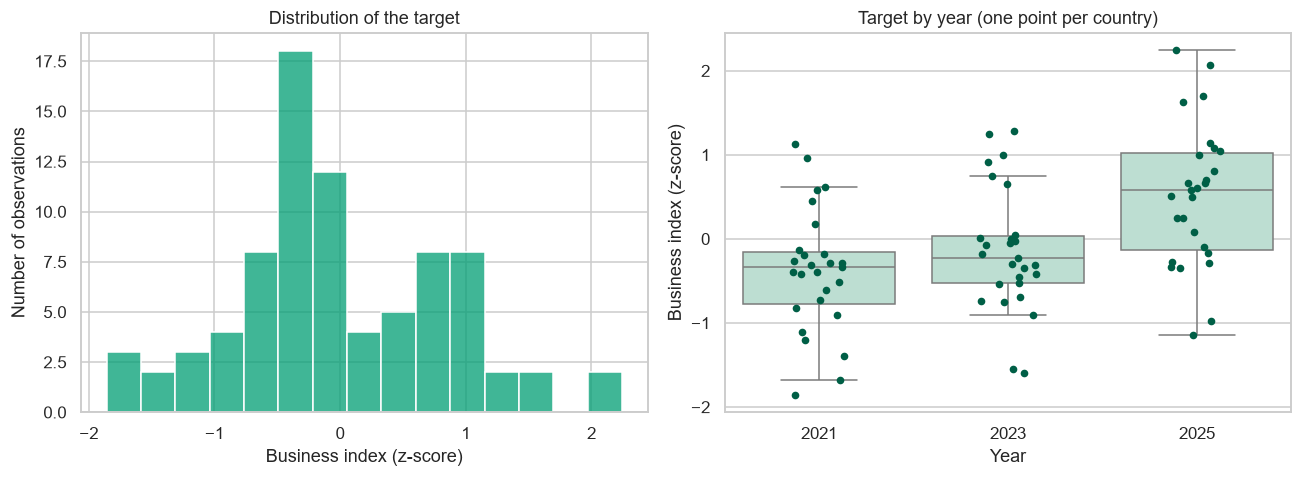

Skewness: 0.28
Mean by year:
year
2021   -0.37
2023   -0.14
2025    0.51


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["business_index"], bins=15, color="#009E73", ax=axes[0])
axes[0].set_xlabel("Business index (z-score)")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("Distribution of the target")

sns.boxplot(data=df, x="year", y="business_index", color="#B7E3D3", fliersize=0, ax=axes[1])
sns.stripplot(data=df, x="year", y="business_index", color="#005F46", size=5, jitter=0.15, ax=axes[1])
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Business index (z-score)")
axes[1].set_title("Target by year (one point per country)")

plt.tight_layout()
save_fig("07_target_distribution")
plt.show()

print("Skewness:", round(df["business_index"].skew(), 2))
print("Mean by year:")
print(df.groupby("year")["business_index"].mean().round(2).to_string())

**c) Rankings.** Do the countries at the top and at the bottom match what you know and what you saw in the EDA? The chart shows the 2025 index for all 27 countries.

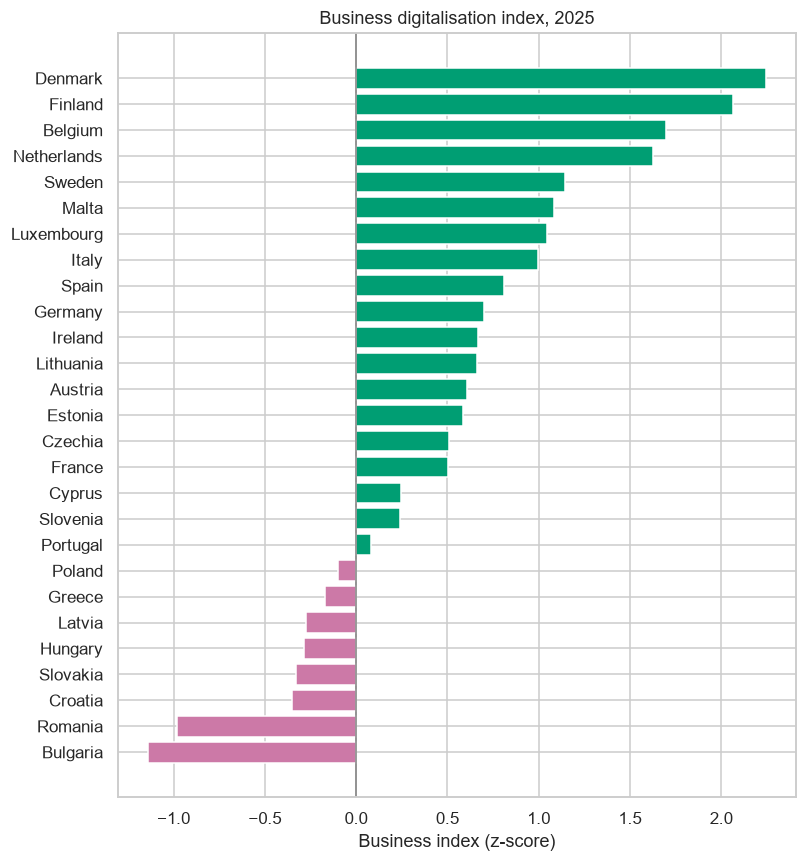

Top 5:    Denmark, Finland, Belgium, Netherlands, Sweden
Bottom 5: Bulgaria, Romania, Croatia, Slovakia, Hungary


In [6]:
rank_2025 = (df[df["year"] == df["year"].max()]
             .set_index("country")["business_index"].sort_values())

fig, ax = plt.subplots(figsize=(7.5, 8))
ax.barh([COUNTRY_NAMES[c] for c in rank_2025.index], rank_2025.values,
        color=["#009E73" if v >= 0 else "#CC79A7" for v in rank_2025.values])
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("Business index (z-score)")
ax.set_title(f"Business digitalisation index, {int(df['year'].max())}")
plt.tight_layout()
save_fig("08_target_ranking_latest_year")
plt.show()

print("Top 5:   ", ", ".join(COUNTRY_NAMES[c] for c in rank_2025.index[::-1][:5]))
print("Bottom 5:", ", ".join(COUNTRY_NAMES[c] for c in rank_2025.index[:5]))

**d) Questions to answer in your own words** (write them in the last section of the notebook):
- Are the leaders and laggards the ones you expected?
- Is any country surprising?
- Is the distribution reasonable, or are there extreme values that could dominate the models?

## 4. Explanatory variables and multicollinearity

The **explanatory variables** (features, `X`) are the factors the models will use to explain the target. As stated in the README they cover:

| Group | Variables |
|---|---|
| Skills | `skills_basic`, `skills_above`, `ict_specialists` |
| Infrastructure | `fttp`, `vhcn`, `gbit5g` |
| Socio-economic (World Bank) | `log_gdp_pc_ppp`, `tertiary_enrol`, `rnd_gdp`, `urban_pop` |

**What is deliberately left out:**
- the four business indicators that make up the target (`sme_digital_intensity`, `cloud`, `ai`, `erp`): including them would be circular;
- `unicorns` and the two public-services indicators: they are outcomes of digitalisation rather than structural factors, and are not in the README's list. They could be added later as a robustness check;
- `services_gdp` and `population`: not part of the research question for now.

In [7]:
FEATURES = [
    # skills
    "skills_basic", "skills_above", "ict_specialists",
    # infrastructure
    "fttp", "vhcn", "gbit5g",
    # socio-economic (World Bank, 1-year lag)
    "log_gdp_pc_ppp", "tertiary_enrol", "rnd_gdp", "urban_pop",
]

# Safety checks: the target components must NOT be among the features
assert not set(FEATURES) & set(TARGET_COMPONENTS), "A target component is among the features!"
missing_cols = [c for c in FEATURES if c not in df.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"

X = df[FEATURES].copy()
y = df["business_index"].copy()
groups = df["country"].copy()

print("X:", X.shape, "| y:", y.shape, "| groups:", groups.nunique(), "countries")
n_incomplete = int(X.isna().any(axis=1).sum())
print("Rows with at least one missing feature:", n_incomplete)
if n_incomplete:
    display(df.loc[X.isna().any(axis=1), ["country", "year"] + [c for c in FEATURES if X[c].isna().any()]])

X: (81, 10) | y: (81,) | groups: 27 countries
Rows with at least one missing feature: 0


**Missing values in the features.** If the cell above lists any rows, they come from World Bank indicators that were not available even after the 1-year lag and the limited forward-fill. We do **not** drop them here: with 81 observations every row counts. In the next notebook they can be filled with a simple imputer (for example the median) placed **inside** the modelling pipeline, so that the fill value is computed only on the training data of each fold and nothing leaks from the test set. Note down which countries and variables are affected: it goes in the README.

**Multicollinearity (VIF).** The Variance Inflation Factor tells how much a variable can be predicted from all the others. Rule of thumb: **VIF above 5** signals notable collinearity and **above 10** a serious one. In the EDA we saw that basic and above-basic skills are almost the same information (r = 0.95), so we expect them at the top of the table. High VIFs do not prevent prediction, but they make the *importance* of individual variables unstable: the model may split the credit between two near-duplicate variables arbitrarily. The VIF is computed on complete rows only.

In [8]:
X_complete = X.dropna()
Xc = sm.add_constant(X_complete)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=X_complete.columns, name="VIF").sort_values(ascending=False)

print(f"VIF computed on {len(X_complete)} complete rows")
display(vif.round(1).to_frame())

VIF computed on 81 complete rows


,VIF
skills_basic,15.6
skills_above,13.5
fttp,3.3
ict_specialists,3.2
vhcn,3.2
log_gdp_pc_ppp,2.6
rnd_gdp,2.0
urban_pop,1.8
tertiary_enrol,1.8
gbit5g,1.4


**What to do with the result.** There is no single right answer; the options are:

1. **Keep everything** and rely on regularised models (Ridge, Lasso, Elastic Net), which are designed to handle correlated variables. Interpret importances with caution (this is already in the README's *Limitations*).
2. **Drop one of two near-duplicates** (for example `skills_above`) and compare results with and without it.
3. **Combine** the near-duplicates into one variable.

A good plan for now: keep all variables, and in the next notebook repeat the main model without the variable with the highest VIF as a **robustness check**.

## 5. Groups and country-grouped cross-validation

The 81 rows are not independent: each country appears **three times** (2021, 2023, 2025), and the three observations of a country are very similar to each other. If a random split put 2021 of Italy in the training set and 2025 of Italy in the test set, the model would "recognise" Italy and the score would be inflated: this is a form of **data leakage**.

The fix is to **split by country**: all three rows of a country go either to the training set or to the test set, never both. The vector `groups` (the country of each row) tells scikit-learn which rows belong together. We use:

- **`GroupKFold`** (5 folds): each fold holds out about 5 or 6 countries;
- **`LeaveOneGroupOut`**: 27 folds, each holds out one country (more demanding, useful to see whether results depend on a single country such as Ireland or Luxembourg).

The cell below checks the two things that matter: that no country appears on both sides of a split, and that every test fold contains complete countries (3 rows each).

In [9]:
def check_splits(splitter, name):
    rows = []
    for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y, groups), start=1):
        train_countries = set(groups.iloc[train_idx])
        test_countries = set(groups.iloc[test_idx])
        assert not train_countries & test_countries, "A country is in both train and test!"
        assert (groups.iloc[test_idx].value_counts() == 3).all(), "A test country is incomplete!"
        rows.append({"fold": fold, "n_train": len(train_idx), "n_test": len(test_idx),
                     "test countries": ", ".join(sorted(test_countries))})
    print(f"{name}: {len(rows)} folds, no country shared between train and test: OK")
    return pd.DataFrame(rows)

folds_gkf = check_splits(GroupKFold(n_splits=5), "GroupKFold(5)")
display(folds_gkf)

folds_logo = check_splits(LeaveOneGroupOut(), "LeaveOneGroupOut")

GroupKFold(5): 5 folds, no country shared between train and test: OK


,fold,n_train,n_test,test countries
0,1,63,18,"BE, DK, FR, LT, PL, SK"
1,2,63,18,"AT, DE, FI, IT, NL, SI"
2,3,66,15,"CZ, ES, IE, MT, SE"
3,4,66,15,"CY, EL, HU, LV, RO"
4,5,66,15,"BG, EE, HR, LU, PT"


LeaveOneGroupOut: 27 folds, no country shared between train and test: OK


**Note on standardisation.** The explanatory variables are **not** standardised here. Scaling must be learned only from the training data of each fold (otherwise the test set would influence the mean and standard deviation used to scale, which is data leakage). In the next notebook the scaler will be part of the modelling **pipeline**, which refits it automatically inside every fold.

## 6. Saving the model data

We save the prepared table (country, year, target and features, unscaled) so the next notebook can start directly from it.

In [10]:
model_data = pd.concat([df[["country", "year"]], y, X], axis=1)
out_path = ROOT / "data" / "processed" / "model_data.csv"
model_data.to_csv(out_path, index=False)

print("Saved:", out_path.relative_to(ROOT), "| shape:", model_data.shape)
model_data.head()

Saved: data\processed\model_data.csv | shape: (81, 13)


,country,year,business_index,skills_basic,skills_above,ict_specialists,fttp,vhcn,gbit5g,log_gdp_pc_ppp,tertiary_enrol,rnd_gdp,urban_pop
0,AT,2021,-0.13,63.33,33.28,4.5,26.62,45.37,76.80,11.01,88.71,3.21,68.54
1,AT,2023,-0.18,64.68,32.04,5.3,40.97,67.62,96.03,11.09,94.51,3.18,69.00
2,AT,2025,0.61,69.77,34.26,5.4,50.88,76.26,99.84,11.06,92.61,3.26,69.47
3,BE,2021,0.46,54.23,26.34,5.6,10.09,68.92,4.25,10.96,79.50,3.37,87.30
4,BE,2023,0.75,59.39,28.26,5.4,25.00,91.20,40.35,11.04,83.57,3.20,87.49


## 7. Checklist before moving on

Tick each item once you can answer it in your own words:

- [ ] I can explain how the target is built and why it is standardised.
- [ ] The four components of the target are correlated, and PC1 explains a large share of their variation.
- [ ] I looked at the ranking and it makes sense (or I noted what looks surprising).
- [ ] I know which variables are in `X`, and why the target's components and the public-services indicators are not.
- [ ] I know which variables have the highest VIF and what I will do about it.
- [ ] I understand why the data are split by country, and that scaling and imputation must happen inside the folds.
- [ ] `data/processed/model_data.csv` has been created.

### What I noticed

- **Is the target reasonable?** Yes. The four components are positively
  correlated (0.43 to 0.89, the strongest link being SMEs' digital intensity
  and cloud use, the weakest ERP), and the first principal component explains
  about 73% of their variance; the index follows it almost perfectly
  (correlation 0.999), so a single index is a reasonable summary. The
  distribution is roughly symmetric (skewness 0.28) with no extreme outliers.
- **Rankings.** In 2025 Denmark, Finland, Belgium, the Netherlands and
  Sweden lead, while Bulgaria, Romania, Croatia, Slovakia and Hungary are at
  the bottom, consistent with what the EDA showed.
- **Time trend.** The mean of the index rises from -0.37 in 2021 to -0.14 in
  2023 and 0.51 in 2025, with the largest jump in the last two years. Since
  all countries move upwards, a common year effect is mixed into the data
  and the models may need to account for it; part of the jump may reflect
  changes in how AI adoption is measured.
- **Explanatory variables.** [Complete with your VIF table: which variables
  exceed 5 or 10, and what you plan to do, e.g. keep them all and rely on
  regularised models, then run a robustness check without the highest-VIF
  variable.] [Complete with your missing values: "no missing values" or the
  countries and variables affected.]
- **Validation.** Splitting by country (GroupKFold with 5 folds of 5-6
  countries, and leave-one-country-out with 27 folds) keeps the three
  observations of each country together, avoiding leakage.
- **Hypotheses to test next:** skills will be the strongest predictor;
  infrastructure will add little once skills and income are controlled for;
  GDP's effect will be non-linear and sensitive to Ireland and Luxembourg.



### Next steps
1. Save the notebook and commit (`git add .`, `git commit -m "Add data preparation for models"`, `git push`).
2. In the README, update the status line and, if useful, add a sentence on the target's construction check.
3. Next notebook (`03_models_baseline.ipynb`): baseline (mean), Ridge/Lasso/Elastic Net with a scaling pipeline and `GroupKFold`, then Random Forest and Gradient Boosting.